In [1]:
import pandas as pd
import numpy as np
import os
from scipy import stats

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_curve,
    auc
)

In [5]:
os.getcwd()
os.chdir('a:\\Dominic\\My Projects\\Home Credit')

In [6]:
creditcard_selection_metrics = pd.read_excel('src\\Variable-Selection\\creditcard_selection_metrics_full.xlsx')

In [7]:
feature_cols = creditcard_selection_metrics.loc[creditcard_selection_metrics['points']>1,'variable']

In [8]:
target_col = 'TARGET'

In [9]:
df = pd.read_parquet('src\\intermediate\\creditcard_processed.parquet')

In [10]:
#temp = df[df['AMT_BALANCE_YOY_PCT_CHANGE_3M_MAX'].isna()]

In [11]:
X = df[feature_cols]
y = df[target_col]

In [12]:
del df

In [13]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials

In [14]:
missing_counts = X.isna().sum()
missing_counts

AMT_BALANCE_3Y_AVG                        0
AMT_RECIVABLE_3Y_AVG                      0
AMT_TOTAL_RECEIVABLE_3Y_AVG               0
CNT_DRAWINGS_ATM_CURRENT_3Y_AVG           0
ATM_DRAWING_AMT_RATIO_3Y_AVG              0
                                         ..
DRAWING_TO_PYMNT_RATIOLAST_MONTH          0
POS_DRAWING_AMT_RATIOLAST_MONTH           0
ATM_DRAWING_AMT_RATIOLAST_MONTH           0
ISNULL_DRAWINGS_CURRENT_FLAGLAST_MONTH    0
NON_ACTIVE_PREV_CREDITS_LAST_1Y           0
Length: 154, dtype: int64

In [15]:
# --- 0. Prepare Sample Data ---
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=1994, stratify=y)

In [16]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import xgboost as xgb

In [24]:
# --- 2. Define the Hyperparameter Search Space ---
space = {
    'n_estimators': hp.quniform('n_estimators', 50, 400, 10),
    'num_leaves': hp.quniform('num_leaves', 20, 60, 2),
    'max_depth': hp.quniform('max_depth', 3, 21, 2),
#    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
#    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.6, 1.0),
    'reg_alpha': hp.uniform('reg_alpha', 0.0, 1.0),
    'reg_lambda': hp.uniform('reg_lambda', 0.0, 1.0),
}

In [ ]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Hyperopt sends integer parameters as floats, so we need to convert them
    params['num_leaves'] = int(params['num_leaves'])
    params['max_depth'] = int(params['max_depth'])
    params['n_estimators'] = int(params['n_estimators'])
    
    # Initialize and train the LightGBM model
    model = lgb.LGBMClassifier(
        objective='binary',
        boosting_type='goss',
    #   metric='logloss',
        device='cpu',
    #   gpu_platform_id=0,      # Usually 0 for first platform
    #   gpu_device_id=0,        # Usually 0 for first device
        seed=42,
        n_jobs=4,
        verbose=-1,
        learning_rate = 0.015,
        subsample = 0.75,
        **params  # Unpack the dictionary of hyperparameters
    )
    
    # Use stratified K-fold for imbalanced datasets
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Get cross-validation scores
    scores = cross_val_score(model, X_train, y_train,
                            scoring='roc_auc', cv=cv, n_jobs=4)
    mean_score = scores.mean()
    # to minimize, we negate the score
    return -mean_score

In [29]:
# --- 3. Run the Optimization ---
# The Trials object will store the history of the search
trials = Trials()

# fmin is the optimization function
best_params = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (Tree-of-Parzen-Estimators)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")
print("Best hyperparameters found:")
# Convert float values back to int for integer parameters
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['max_depth'] = int(best_params['max_depth'])
print(best_params)

100%|██████████| 150/150 [1:38:24<00:00, 39.37s/trial, best loss: -0.6597962904391752]   

--- Hyperopt Search Complete ---
Best hyperparameters found:
{'colsample_bytree': np.float64(0.660266015001885), 'max_depth': 6, 'n_estimators': 400, 'num_leaves': 42, 'reg_alpha': np.float64(0.7329986179515006), 'reg_lambda': np.float64(0.6320822056282963)}


In [43]:
from lightgbm.callback import early_stopping, log_evaluation
from sklearn.metrics import f1_score

In [31]:
# Define the custom evaluation function for F1-score
def lgb_f1_score(y_true, y_pred):
    """
    Custom F1 score metric for LightGBM.
    """
    # y_pred will be probabilities, so we need to convert them to 0/1 predictions
    # using a standard 0.5 threshold.
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred)

    # Calculate F1-score for each threshold
    # Note: We add a small epsilon to avoid division by zero
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

    # Find the threshold that maximizes the F1-score
    best_f1_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_f1_idx]
    best_f1_score = f1_scores[best_f1_idx]

    y_pred_binary = (y_pred > best_threshold).astype(int)
    
    # Calculate F1 score
    score = f1_score(y_true, y_pred_binary)
    
    # The return format is (metric_name, metric_value, is_higher_better)
    return 'f1', score, True

In [34]:
# Initialize a new model with the best parameters
final_model = lgb.LGBMClassifier(
    objective='binary',
    seed=1994,
    **best_params               # Unpack the best parameters
)

final_model.fit(
    X_train, y_train,          # Training data
    eval_set=[(X_val, y_val)], # Validation data to monitor
    eval_metric='auc',         # Metric to track
    callbacks=[
        # Stop training if the 'auc' on the validation set
        # doesn't improve for 50 consecutive rounds.
        early_stopping(stopping_rounds=50),

        # Print the evaluation metric every 20 rounds.
        log_evaluation(period=20)
    ]
)

# Evaluate on test set
y_pred_proba = final_model.predict_proba(X_val)[:, 1]
test_auc = roc_auc_score(y_val, y_pred_proba)
print(f"Test AUC: {test_auc:.4f}")

[LightGBM] [Info] Number of positive: 6072, number of negative: 63889
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020003 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17883
[LightGBM] [Info] Number of data points in the train set: 69961, number of used features: 85
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.086791 -> initscore=-2.353459
[LightGBM] [Info] Start training from score -2.353459
Training until validation scores don't improve for 50 rounds
[20]	valid_0's auc: 0.652976	valid_0's binary_logloss: 0.282188
[40]	valid_0's auc: 0.651604	valid_0's binary_logloss: 0.282732
[60]	valid_0's auc: 0.653814	valid_0's binary_logloss: 0.282496
Early stopping, best iteration is:
[23]	valid_0's auc: 0.653686	valid_0's binary_logloss: 0.282154
Test AUC: 0.6537


In [35]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1148
F1-Score at this threshold: 0.2452

--- Performance at Optimal Threshold (0.11) ---
              precision    recall  f1-score   support

           0       0.93      0.84      0.88     15973
           1       0.18      0.38      0.25      1518

    accuracy                           0.80     17491
   macro avg       0.56      0.61      0.56     17491
weighted avg       0.87      0.80      0.83     17491



In [36]:
# Create a DataFrame to view feature importances clearly
importances = pd.DataFrame({
    'feature': final_model.feature_name_,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("Feature importances:")
print(importances)

Feature importances:
                                           feature  importance
0   CREDITCARD_FIRST_MONTH_AMT_CREDIT_LIMIT_ACTUAL          39
1            CREDITCARD_FIRST_MONTH_MONTHS_BALANCE          36
2          CREDITCARD_LAST_MONTH_UTILIZATION_RATIO          29
3       CREDITCARD_LAST_MONTH_CNT_DRAWINGS_CURRENT          27
4              CREDITCARD_LAST_MONTH_PAYMENT_RATIO          25
..                                             ...         ...
80                 CREDITCARD_AVG_LY_POSAMT_RATE_y           0
81           CREDITCARD_AVG_LS_REPAYMENTCOUNT_RATE           0
82      CREDITCARD_LAST_MONTH_AMT_TOTAL_RECEIVABLE           0
83                  CREDITCARD_LAST_MONTH_DPD_GE_1           0
84                 CREDITCARD_FIRST_MONTH_DPD_GE_7           0

[85 rows x 2 columns]


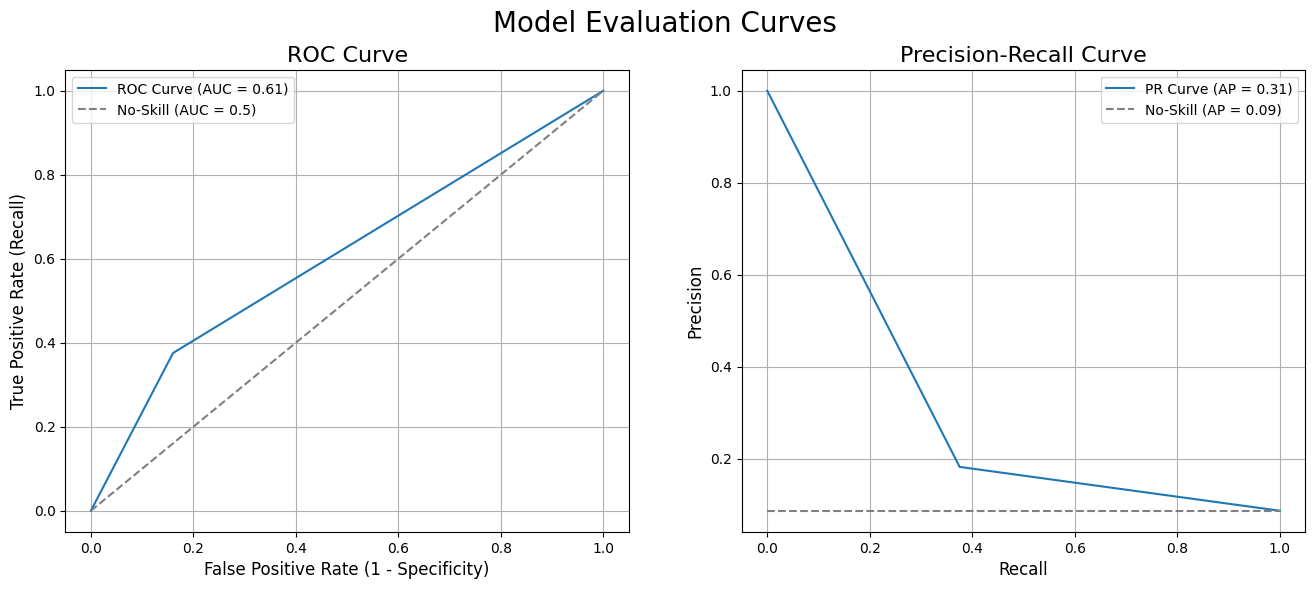

In [37]:
# For ROC Curve
y_pred_proba = y_pred_optimal
fpr, tpr, roc_thresholds = roc_curve(y_val, y_pred_proba)
roc_auc = roc_auc_score(y_val, y_pred_proba)

# For Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_pred_proba)
pr_auc = auc(recall, precision)

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: ROC Curve ---
ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend()
ax1.grid(True)

# --- Plot 2: Precision-Recall Curve ---
ax2.plot(recall, precision, label=f'PR Curve (AP = {pr_auc:.2f})')
no_skill = len(y_val[y_val==1]) / len(y_val)
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend()
ax2.grid(True)

# Add a main title and show the plot
fig.suptitle('Model Evaluation Curves', fontsize=20)
plt.show()

In [23]:
# 4. Calculate and print metrics
print(f"Accuracy: {accuracy_score(y_val, y_pred_labels):.4f} (Can be misleading on imbalanced data)\n")

# Metrics that require probabilities
print(f"AUC Score: {roc_auc_score(y_val, y_pred_labels):.4f}")
print(f"Log Loss: {log_loss(y_val, y_pred_labels):.4f}\n")

# Metrics that require binary labels
print(f"Precision: {precision_score(y_val, y_pred_labels):.4f}")
print(f"Recall (Sensitivity): {recall_score(y_val, y_pred_labels):.4f}")
print(f"F1-Score: {f1_score(y_val, y_pred_labels):.4f}\n")

NameError: name 'y_pred_labels' is not defined

In [46]:
from sklearn.naive_bayes import GaussianNB

# 1. Initialize the model
nb = GaussianNB()

# 2. Train the model
print("Training Naive Bayes...")
nb.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred_proba = nb.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)

print(f"\nNaive Bayes AUC Score: {auc:.4f}")

Training Naive Bayes...

Naive Bayes AUC Score: 0.5997


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [ ]:
# Handle missing values
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.20, random_state=17,stratify=y)

# Fit logistic regression model
model = LogisticRegression(random_state=124, max_iter=10000, penalty='l1', solver='liblinear', C=0.1)
model.fit(X_train, y_train)

# Create DataFrame with coefficients
coef_df = pd.DataFrame({'variable': feature_cols, 'coef': model.coef_[0]})

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [49]:
y_pred_proba = model.predict_proba(X_val)[:, 1]  # This will give the predicted probabilities for the validation set

In [50]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1335
F1-Score at this threshold: 0.2444

--- Performance at Optimal Threshold (0.13) ---
              precision    recall  f1-score   support

           0       0.93      0.86      0.90     15973
           1       0.19      0.34      0.24      1518

    accuracy                           0.82     17491
   macro avg       0.56      0.60      0.57     17491
weighted avg       0.87      0.82      0.84     17491



In [51]:
roc_auc = roc_auc_score(y_val, y_pred_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

ROC AUC Score: 0.6402


In [30]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Hyperopt sends integer parameters as floats, so we need to convert them
    params['num_leaves'] = int(params['num_leaves'])
    params['max_depth'] = int(params['max_depth'])
    params['n_estimators'] = int(params['n_estimators'])
    
    # Initialize the XGBoost model
    model = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        random_state=42,
        use_label_encoder=False,
        n_jobs=-1,
        **params  # Unpack the dictionary of hyperparameters
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    mean_auc = cross_val_score(model, X_train, y_train,
                               scoring='roc_auc', cv=cv, n_jobs=-1).mean()

    # Return the standard Hyperopt dictionary format
    return {'loss': -mean_auc, 'status': STATUS_OK}

In [31]:
# --- 3. Run the Optimization ---
# The Trials object will store the history of the search
trials = Trials()

# fmin is the optimization function
best_params = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (Tree-of-Parzen-Estimators)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")
print("Best hyperparameters found:")
# Convert float values back to int for integer parameters
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['max_depth'] = int(best_params['max_depth'])
print(best_params)

100%|██████████| 150/150 [30:16<00:00, 12.11s/trial, best loss: -0.6650535181582229]

--- Hyperopt Search Complete ---
Best hyperparameters found:
{'colsample_bytree': np.float64(0.8714610650925534), 'max_depth': 3, 'n_estimators': 50, 'num_leaves': 57, 'reg_alpha': np.float64(0.4749466419949838), 'reg_lambda': np.float64(0.14089776932425035)}


In [56]:
best_params  = {
    'colsample_bytree': np.float64(0.8714610650925534), 
    'max_depth': 3, 
    'n_estimators': 50, 
    'num_leaves': 57, 
    'reg_alpha': np.float64(0.4749466419949838), 
    'reg_lambda': np.float64(0.14089776932425035)
    }

In [57]:
# 1. Initialize the XGBoost model
# 'eval_metric' is set to avoid a future deprecation warning.
xgboost_model = xgb.XGBClassifier(
    random_state=42,
    eval_metric='auc',
    **best_params
)

# 2. Train the model
print("Training XGBoost...")
xgboost_model.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred_proba = xgboost_model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)

print(f"\nXGBoost AUC Score: {auc:.4f}")

Training XGBoost...


a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:52:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "num_leaves" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost AUC Score: 0.6526


In [58]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1082
F1-Score at this threshold: 0.2439

--- Performance at Optimal Threshold (0.11) ---
              precision    recall  f1-score   support

           0       0.94      0.82      0.87     15973
           1       0.17      0.40      0.24      1518

    accuracy                           0.78     17491
   macro avg       0.55      0.61      0.56     17491
weighted avg       0.87      0.78      0.82     17491

